In [1]:
import math, os, time
import torch
import torch.nn as nn
from torch.nn import functional as F

torch.manual_seed(1337)          # reproducibility (same seed as every ME324 lab)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '| device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU — Runtime > Change runtime type > GPU (everything still runs on CPU, just slower).')

PyTorch 2.14.1+cpu | device: cpu
No GPU — Runtime > Change runtime type > GPU (everything still runs on CPU, just slower).


## The data

The corpus is **every attributed speech from five sitting days of the House of Commons** (9–16 July 2026), which equates to about 2.1 million characters. The format is always speaker name, colon, speech.

(The data was sourced via TheyWorkForYou.)

In [2]:
!wget -nc https://raw.githubusercontent.com/tsrobinson/me324/main/assessment/data/hansard-2026.txt -O hansard.txt

with open('hansard.txt', 'r', encoding='utf-8') as f:
    text = f.read()

print('total characters:', len(text))
print('---- first 500 characters ----')
print(text[:500])

--2026-11-15 18:41:50--  https://raw.githubusercontent.com/tsrobinson/me324/main/assessment/data/hansard-2026.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2092113 (2.0M) [text/plain]
Saving to: ‘hansard.txt’

hansard.txt         100%[===================>]   2.00M  --.-KB/s    in 0.02s   

2026-11-15 18:41:50 (124 MB/s) - ‘hansard.txt’ saved [2092113/2092113]

total characters: 2091809
---- first 500 characters ----
Dave Robertson:
What steps she is taking to support the long-term financial sustainability of farm businesses.

Anna Gelderd:
What steps she is taking to support the long-term financial sustainability of farm businesses.

Emma Reynolds:
My hon. Friend the Member for Portsmouth South (Stephen Morgan), the new farming and food Minister, and I

In [3]:
chars = sorted(set(text))
print('vocab size:', len(chars))         # slightly different from our Shakespeare corpus
print(repr(''.join(chars)))

vocab size: 83
'\n !"$%&\'()+,-./0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]abcdefghijklmnopqrstuvwxyz£'


In [4]:
def build_char_pipeline(text, block_size=8, batch_size=32, device="cpu", seed=1337):
    """Char-level tokenizer + batcher + loss estimator. (Lab 8, unchanged.)"""
    torch.manual_seed(seed)
    chars = sorted(set(text))
    vocab_size = len(chars)
    stoi = {ch: i for i, ch in enumerate(chars)}        # char  -> integer id
    itos = {i: ch for i, ch in enumerate(chars)}        # id    -> char
    encode = lambda s: [stoi[c] for c in s]             # string -> list[int]
    decode = lambda l: ''.join(itos[i] for i in l)      # list[int] -> string
    data = torch.tensor(encode(text), dtype=torch.long)
    n = int(0.9 * len(data))
    train_data, val_data = data[:n], data[n:]           # 90% train / 10% val

    def get_batch(split):
        d = train_data if split == 'train' else val_data
        ix = torch.randint(len(d) - block_size, (batch_size,))      # random starts
        x = torch.stack([d[i:i + block_size] for i in ix])          # (B, block_size)
        y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])  # shifted by one
        return x.to(device), y.to(device)

    @torch.no_grad()
    def estimate_loss(model, eval_iters=200):
        out = {}
        model.eval()
        for split in ['train', 'val']:
            losses = torch.zeros(eval_iters)
            for k in range(eval_iters):
                xb, yb = get_batch(split)
                _, loss = model(xb, yb)
                losses[k] = loss.item()
            out[split] = losses.mean().item()
        model.train()
        return out

    return dict(vocab_size=vocab_size, stoi=stoi, itos=itos, encode=encode,
                decode=decode, get_batch=get_batch, estimate_loss=estimate_loss,
                block_size=block_size, device=device)

In [5]:
def train_model_tracked(model, get_batch, estimate_loss, max_iters=3000, eval_interval=500,
                        lr=1e-3, device="cpu"):
    """The labs' train_model, plus a record: returns (model, history), where history
    is a list of (iteration, train_loss, val_loss) tuples."""
    history = []
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    for it in range(max_iters):
        if it % eval_interval == 0 or it == max_iters - 1:
            losses = estimate_loss(model)
            history.append((it, losses['train'], losses['val']))
            print(f"step {it:5d} | train {losses['train']:.4f} | val {losses['val']:.4f}")
        xb, yb = get_batch('train')
        _, loss = model(xb, yb)                 # forward: model -> (logits, loss)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()                         # backward: autograd
        optimizer.step()                        # update weights
    return model, history

In [6]:
import matplotlib.pyplot as plt

def plot_histories(runs, title=""):
    """runs: dict of label -> history, e.g. {'block=8': h8, 'block=64': h64}."""
    plt.figure(figsize=(7, 4))
    for label, hist in runs.items():
        its = [h[0] for h in hist]
        plt.plot(its, [h[1] for h in hist], '--', alpha=0.5, label=f'{label} · train')
        plt.plot(its, [h[2] for h in hist], '-', label=f'{label} · val')
    plt.xlabel('iteration'); plt.ylabel('loss'); plt.title(title)
    plt.legend(); plt.grid(alpha=0.3); plt.show()

def count_params(model):
    """Every trainable parameter, biases included (house rule)."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### The bigram baseline

Here's Lab 8's bigram. Train it and uise the validation loss as the threshold for your Part A model to beat.

In [7]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        # one row of next-char scores per character: no context, no memory.
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)            # (B, T, vocab)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            logits = logits[:, -1, :]                       # last position only
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

print('Bigram defined — same model as Lab 8.')

Bigram defined — same model as Lab 8.


In [8]:
P = build_char_pipeline(text, block_size=8, batch_size=32, device=device)

torch.manual_seed(1337)
bigram = BigramLanguageModel(P['vocab_size']).to(device)
print('parameters:', count_params(bigram))

bigram, bigram_history = train_model_tracked(bigram, P['get_batch'], P['estimate_loss'],
                                             max_iters=3000, eval_interval=500, lr=1e-2,
                                             device=device)
baseline = P['estimate_loss'](bigram)
print(f"\nBASELINE | val loss {baseline['val']:.4f} | per-char perplexity {math.exp(baseline['val']):.1f}")

parameters: 6889
step     0 | train 4.8288 | val 4.8362
step   500 | train 2.5526 | val 2.5785
step  1000 | train 2.4536 | val 2.4862
step  1500 | train 2.4445 | val 2.4632
step  2000 | train 2.4324 | val 2.4508
step  2500 | train 2.4235 | val 2.4468
step  2999 | train 2.4143 | val 2.4547

BASELINE | val loss 2.4415 | per-char perplexity 11.5


In [9]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)   # start token = id 0
print(P['decode'](bigram.generate(context, max_new_tokens=400)[0].tolist()))


Ch Parint. cof mar an orye frlpthalie C persiQ0 Fron ok ermortocarcly aveghequs wndald ame ge he ie be abousts were wor Norto cloras watast oritingy chewers Frk merig Houtthy whe:
Mid buing d Honduce wh herendeant aty?
Thormer7. doue id - alig the stlo t t braghe acevin be aces temacllenkindvissereCofave Sin sckneaty. sthe clde pr lisser sino ars I wiengnghes whaten wavid bley s re d haf plecowann


In [10]:
class MyLanguageModel(nn.Module):
    """Your model. The contract, same as every ME324 language model:


      forward(idx, targets=None) -> (logits, loss)
          idx: (B, T) integer ids; logits: (B, T, vocab_size);
          loss: cross-entropy over all positions if targets is given, else None.
      generate(idx, max_new_tokens) -> (B, T + max_new_tokens) integer ids


    Character-level feedforward language model.
    Strategy: Embed a context window of characters, flatten them,
    pass through a small MLP, predict the next character.
    """
    def __init__(self, vocab_size, hidden_dim=128, dropout=0.0):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, 64)
        self.rnn = nn.GRU(64, hidden_dim, batch_first=True, dropout=dropout)
        self.linear = nn.Linear(hidden_dim, vocab_size)


    def forward(self, idx, targets=None):
        x = self.token_embedding_table(idx)
        x, _ = self.rnn(x)
        x = F.relu(x)
        logits = self.linear(x)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss


    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= P['block_size'] else idx[:, -P['block_size']:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [11]:
P = build_char_pipeline(text, block_size=8, batch_size=32, device=device)

torch.manual_seed(1337)
model = MyLanguageModel(P['vocab_size']).to(device)
n_params = count_params(model)
print(f'parameters: {n_params:,} / 500,000')
assert n_params <= 500_000, 'over budget - slim it down'


parameters: 90,515 / 500,000


In [12]:
# TODO: choose your training hyperparameters.
model, model_history = train_model_tracked(model, P['get_batch'], P['estimate_loss'],
                                           max_iters=3000, eval_interval=500, lr=1e-3,
                                           device=device)

step     0 | train 4.4405 | val 4.4409
step   500 | train 2.1936 | val 2.2171
step  1000 | train 2.0334 | val 2.0813
step  1500 | train 1.9365 | val 2.0061
step  2000 | train 1.8977 | val 1.9653
step  2500 | train 1.8646 | val 1.9471
step  2999 | train 1.8204 | val 1.9035


yours    | train 1.8284 | val 1.9213 | perplexity 6.8
baseline | val 2.4415 | perplexity 11.5


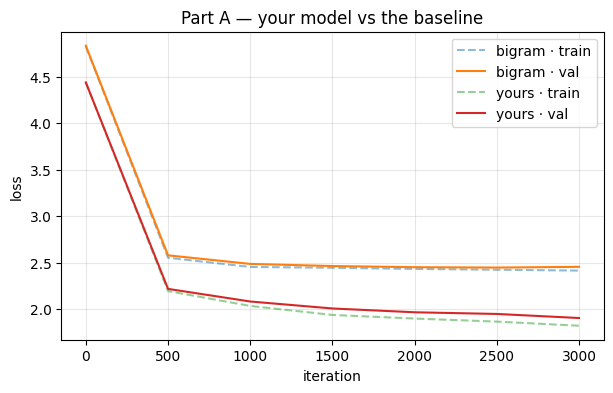


I be an who pores, I orging to be caphandere, so to shoutrous S mornenced, Hough that those math - vitity, will Elling rave as and way. Those strest honal did will gototing the proted are mud nownu use of the ores the Peaving oundit. Wosted out councy ads not that would is that out, by finies approvedsimatis a requect mistroung, how, my Comming, Prumet fade will anition prorgoing an of or Stace Hu


In [13]:
final = P['estimate_loss'](model)
print(f"yours    | train {final['train']:.4f} | val {final['val']:.4f} | perplexity {math.exp(final['val']):.1f}")
print(f"baseline | val {baseline['val']:.4f} | perplexity {math.exp(baseline['val']):.1f}")

plot_histories({'bigram': bigram_history, 'yours': model_history},
               title='Part A — My model vs the baseline')

context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(P['decode'](model.generate(context, max_new_tokens=400)[0].tolist()))

In [14]:
bundle = dict(state_dict=model.state_dict(),
              block_size=P['block_size'],
              n_params=n_params,
              val_loss=final['val'])
torch.save(bundle, 'me324-midterm-checkpoint.pt')
print(f"saved me324-midterm-checkpoint.pt ({os.path.getsize('me324-midterm-checkpoint.pt')/1e6:.1f} MB)")

saved me324-midterm-checkpoint.pt (0.4 MB)


In [15]:
# Verify your submission — the same checks we run on receipt. Leave this cell in.
b = torch.load('me324-midterm-checkpoint.pt', map_location='cpu', weights_only=True)

n = sum(t.numel() for t in b['state_dict'].values())
assert n <= 500_000, f'over budget: {n:,}'

banned = [k for k in b['state_dict']
          if any(s in k.lower() for s in ('attn', 'attention', 'in_proj', 'q_proj', 'k_proj', 'v_proj'))]
assert not banned, f'attention-like modules found: {banned}'

check = MyLanguageModel(P['vocab_size'])         # constructor defaults must rebuild your shapes
check.load_state_dict(b['state_dict'])
check.to(device)

P_check = build_char_pipeline(text, block_size=b['block_size'], batch_size=32, device=device)
torch.manual_seed(1337)
recomputed = P_check['estimate_loss'](check)['val']
print(f"recomputed val {recomputed:.4f} | reported {b['val_loss']:.4f} | baseline {baseline['val']:.4f}")
assert abs(recomputed - b['val_loss']) < 0.05, 'reported loss does not match the checkpoint'
assert recomputed <= baseline['val'] - 0.1, 'does not beat the baseline by 0.1'
print('all submission checks passed')

recomputed val 1.9156 | reported 1.9213 | baseline 2.4415
all submission checks passed



The results show that having a 128 layer performs slightly better than 64 layer, with a validation costs of 1.8768 compared to 1.9767, so de difference is only 0.10. So my hypotesis was correct and we can say that increasing capacit would improve performance, however, the imporovement is not significant. This suggest that hidden_dim=64 is sufficient to achive 95% of the performance with half the parameters. The model with hidden_dim=128 was likely overcapacity, so the extra 64 hidden dimensions provide minimal benefit while consumming more memory and parameters. For practical purposes, hidden_dim=64 represents a  good trade off between model capacity and efficiency, acheving nearly equivalent result on parlimentary text while being leaner and more deployable.

There is a small gap between the training and validation line, so we can think that there might be a little bit of overfiting with complexity. But if we look closer we se that: hidden_dim=64 shows a larger gap between training (1.6875) and validation loss (1.9767), while hidden_dim=128 has a smaller gap (1.7896 vs 1.8768), indicating better generalization. The larger model doesn't overfit instead, the smaller model lacks capacity to properly learn the data. Therefore, hidden_dim=128 is superior not just in performance but also in robustness. So we might have a little bit of overfitting but improves as the model gets more complex.